# Đặc trưng không gian và dự báo ML — validation

Chỉ dùng validation; chưa chấm test ML. Đọc cùng `docs/spatial_ml_design.md` và `docs/ml_validation_results.md`.

Centroid và mật độ lấy từ lịch sử train, giữ region gốc của AOI đa region. Mật độ: đơn/AOI/ngày quan sát.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
OUT = ROOT / 'outputs/forecasts/ml_validation'
folder = OUT / 'primary_stable_period'
protocol = json.loads((folder / 'protocol.json').read_text(encoding='utf-8'))
assert protocol['test_scored'] is False
display(pd.Series({k:protocol[k] for k in ['selected_ml','selected_baseline','training_rows','validation_rows','test_scored']}))

selected_ml           lightgbm_full
selected_baseline    rolling_mean_7
training_rows                  1804
validation_rows                 820
test_scored                   False
dtype: object

## So sánh trên cùng tập ô

MAE là sai số tuyệt đối trung bình (đơn/ô). RMSE nhạy hơn với sai số lớn. WAPE là tổng độ lớn sai số chia tổng đơn. WAPE region tính sau khi cộng các loại AOI; sai số trái dấu có thể bù nhau.

,scenario,split,level,model,mae,rmse,wape,rows,actual_orders
25,primary_stable_period,validation,region,rolling_mean_7,9.098214,12.655573,0.137332,80,5300.0
27,primary_stable_period,validation,region,rolling_mean_14,9.570536,13.331591,0.144461,80,5300.0
1,primary_stable_period,validation,region,lightgbm_full,10.634195,13.965626,0.160516,80,5300.0
11,primary_stable_period,validation,region,xgboost_full,10.781276,14.172122,0.162736,80,5300.0
29,primary_stable_period,validation,region,historical_mean,11.563362,15.327102,0.174541,80,5300.0
31,primary_stable_period,validation,region,historical_weekday,12.073264,15.497311,0.182238,80,5300.0
23,primary_stable_period,validation,region,seasonal_7,12.550000,16.610990,0.189434,80,5300.0
21,primary_stable_period,validation,region,naive_1,13.262500,17.337459,0.200189,80,5300.0
24,primary_stable_period,validation,series,rolling_mean_7,1.371603,3.419890,0.212210,820,5300.0
26,primary_stable_period,validation,series,rolling_mean_14,1.420122,3.595827,0.219717,820,5300.0


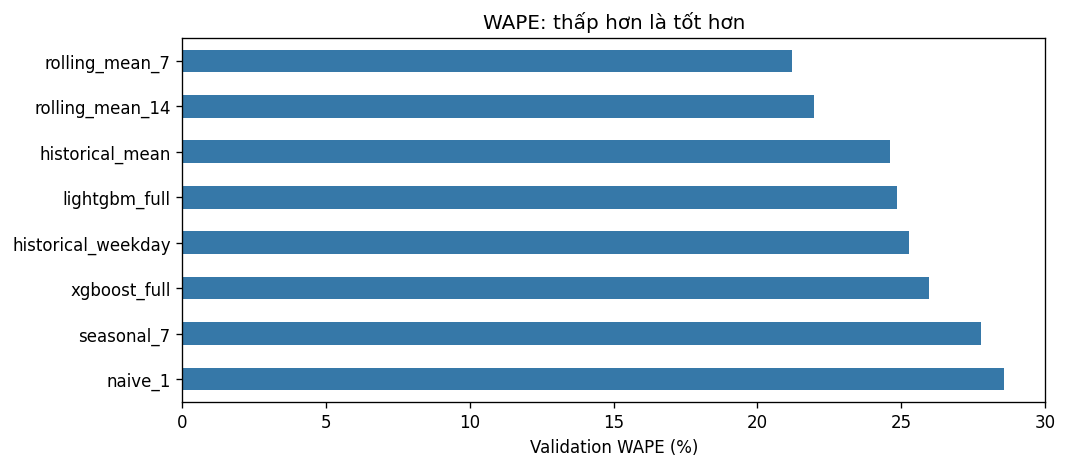

In [2]:
metrics = pd.read_csv(folder / 'validation_metrics.csv')
assert set(metrics['split']) == {'validation'}
full = metrics[~metrics.model.str.contains('_without_')]
display(full.sort_values(['level','wape']))
series = full[full.level == 'series'].sort_values('wape')
ax = series.set_index('model').wape.mul(100).plot.barh(figsize=(9,4), color='#3678a8')
ax.invert_yaxis()
ax.set(xlabel='Validation WAPE (%)', ylabel='', title='WAPE: thấp hơn là tốt hơn')
plt.tight_layout()
plt.show()

## Bỏ lần lượt nhóm đặc trưng

Mỗi biến thể chọn lại từ cùng tám cấu hình. Delta = WAPE bỏ nhóm − WAPE full. Delta âm nghĩa bỏ nhóm giúp giảm sai số trên validation này; không phải bằng chứng nhân quả.

,model,wape,delta_wape_vs_full
0,lightgbm_without_calendar,0.248403,-0.000311
1,lightgbm_without_lag,0.251206,0.002492
2,lightgbm_without_rolling,0.253136,0.004422
3,lightgbm_without_spatial,0.244297,-0.004417
4,xgboost_without_calendar,0.260112,0.000291
5,xgboost_without_lag,0.251015,-0.008806
6,xgboost_without_rolling,0.261994,0.002172
7,xgboost_without_spatial,0.261714,0.001893


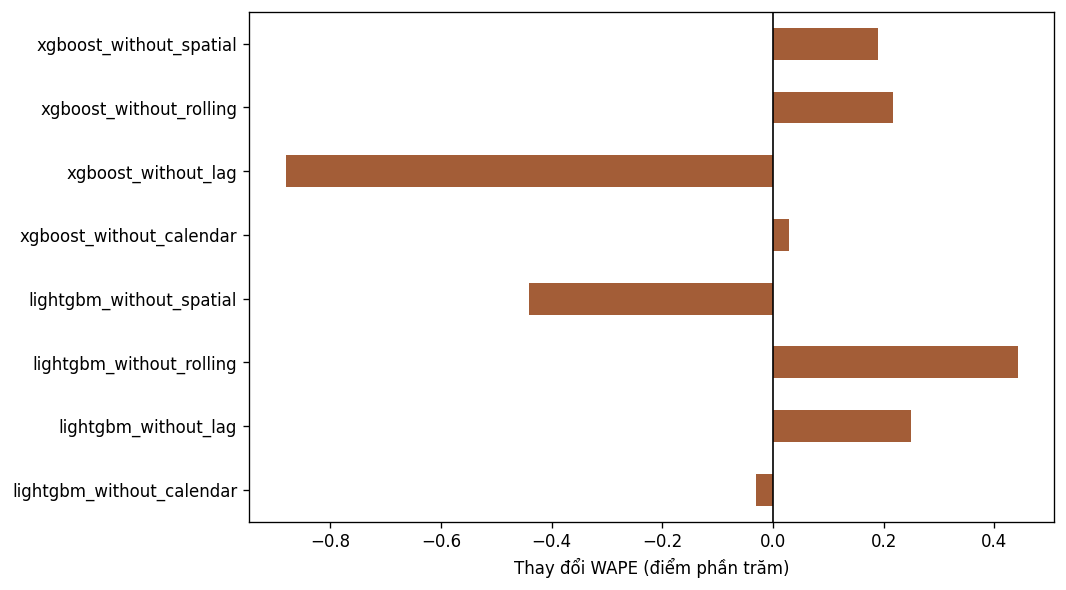

In [3]:
ablation = pd.read_csv(folder / 'validation_ablation.csv')
display(ablation[['model','wape','delta_wape_vs_full']])
ax = ablation.set_index('model').delta_wape_vs_full.mul(100).plot.barh(figsize=(9,5), color='#a35d37')
ax.axvline(0,color='black',linewidth=1)
ax.set(xlabel='Thay đổi WAPE (điểm phần trăm)',ylabel='')
plt.tight_layout()
plt.show()

## Importance và nhóm nhu cầu

Gain là độ giảm loss trên train, chuẩn hoá trong từng mô hình. Biến tương quan có thể chia sẻ vai trò. Nhóm nhu cầu dựa trên trung bình train, không dựa trên validation/test.

In [4]:
gain = pd.read_csv(folder / 'gain_importance.csv')
display(gain[gain.model.eq(protocol['selected_ml'])].sort_values('gain_share',ascending=False))
display(pd.read_csv(folder / 'validation_demand_bands.csv'))
features = pd.read_parquet(folder / 'features_train_validation.parquet')
assert set(features['split']) == {'train','validation'}
display(features.groupby(['split','spatial_fallback']).size().rename('rows').to_frame())

,feature,gain,gain_share,model
12,rolling_mean_14,1.333657e+06,3.643038e-01,lightgbm_full
13,rolling_mean_7,1.209380e+06,3.303561e-01,lightgbm_full
7,lag_1,9.142444e+05,2.497364e-01,lightgbm_full
14,rolling_std_14,1.280691e+05,3.498356e-02,lightgbm_full
1,centroid_lat,2.986260e+04,8.157316e-03,lightgbm_full
9,lag_7,1.841469e+04,5.030187e-03,lightgbm_full
8,lag_14,1.140434e+04,3.115227e-03,lightgbm_full
15,rolling_std_7,9.979817e+03,2.726103e-03,lightgbm_full
3,day_of_month,2.910083e+03,7.949228e-04,lightgbm_full
5,historical_density,1.568928e+03,4.285707e-04,lightgbm_full


,model,band,mae,rmse,wape,rows,actual_orders
0,lightgbm_full,high,3.992972,6.640461,0.216673,280,5160.0
1,lightgbm_full,low,0.220101,0.318989,2.870885,300,23.0
2,lightgbm_full,medium,0.558834,0.697268,1.146325,240,117.0
3,rolling_mean_7,high,3.390816,5.806513,0.183998,280,5160.0
4,rolling_mean_7,low,0.143333,0.314177,1.869565,300,23.0
5,rolling_mean_7,medium,0.551190,0.708428,1.130647,240,117.0


rows
split      spatial_fallback      
train      0                 1512
           1                  292
validation 0                  760
           1                   60

## Cửa sổ toàn kỳ và kết luận

ML full hiện chưa vượt rolling baseline ở cả hai cửa sổ. Đây là kết quả phát triển, chưa thay thế đánh giá test. Độ nhạy toàn kỳ khác A/B giữ đủ tám đơn; A/B ML chưa chạy.

In [5]:
other = pd.read_csv(OUT / 'sensitivity_full_period/validation_metrics.csv')
display(other[(other.level == 'series') & other.model.isin(['rolling_mean_7','lightgbm_full','xgboost_full'])])

,scenario,split,level,model,mae,rmse,wape,rows,actual_orders
0,sensitivity_full_period,validation,series,lightgbm_full,1.554689,3.601874,0.246979,1394,8775.0
10,sensitivity_full_period,validation,series,xgboost_full,1.600737,3.605768,0.254294,1394,8775.0
24,sensitivity_full_period,validation,series,rolling_mean_7,1.304263,3.097209,0.207196,1394,8775.0
